# SPHEREx two-epoch image analysis

This notebook starts the scientific analysis of two SPHEREx calibrated FITS cutouts. It visualizes the IMAGE extensions, checks metadata/WCS, detects candidate sources, and exports measured sky positions. **Detections are not confirmed moving objects.** Image registration, cross-matching, uncertainty checks and validation are required before claiming motion.

Upload both original `.fits` files when prompted. Do not rename or modify the originals.


In [1]:
!pip -q install astropy photutils
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder
from google.colab import files

uploaded = files.upload()
fits_files = [name for name in uploaded if name.lower().endswith(('.fits','.fit','.fits.gz'))]
print('FITS files:', fits_files)
if len(fits_files) != 2:
    print('Please upload exactly the two SPHEREx FITS files for this first comparison.')


Saving level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits to level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits
Saving level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-241.fits to level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-241.fits
FITS files: ['level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits', 'level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-241.fits']


In [2]:
def inspect_fits(path):
    hdul = fits.open(path)
    print('\nFILE:', path)
    hdul.info()
    for i, hdu in enumerate(hdul):
        if hdu.data is not None:
            print(i, hdu.name, 'shape=', hdu.data.shape, 'BUNIT=', hdu.header.get('BUNIT'),
                  'DATE-OBS=', hdu.header.get('DATE-OBS'), 'MJD-OBS=', hdu.header.get('MJD-OBS'))
    return hdul

hduls = [inspect_fits(f) for f in fits_files]



FILE: level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits
Filename: level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       239   (58, 59)   float32   
  2  FLAGS         1 ImageHDU       146   (58, 59)   int32   
  3  VARIANCE      1 ImageHDU       119   (58, 59)   float32   
  4  ZODI          1 ImageHDU       119   (58, 59)   float32   
  5  PSF           1 ImageHDU       509   (101, 101, 121)   float32   
  6  WCS-WAVE      1 BinTableHDU     18   1R x 3C   [9J, 9J, 162E]   
1 IMAGE shape= (59, 58) BUNIT= MJy / sr DATE-OBS= 2025-05-09T03:53:15.489 MJD-OBS= 60804.161984826
2 FLAGS shape= (59, 58) BUNIT=  DATE-OBS= 2025-05-09T03:53:15.489 MJD-OBS= 60804.161984826
3 VARIANCE shape= (59, 58) BUNIT= MJy2 / sr2 DATE-OBS= 2025-05-09T03:53:15.489 MJD-OBS= 60804.161984826
4 ZODI shape= (59, 58) BUNIT= MJy / sr DATE-OBS= 2025-05-09T03:53:15.489 MJ

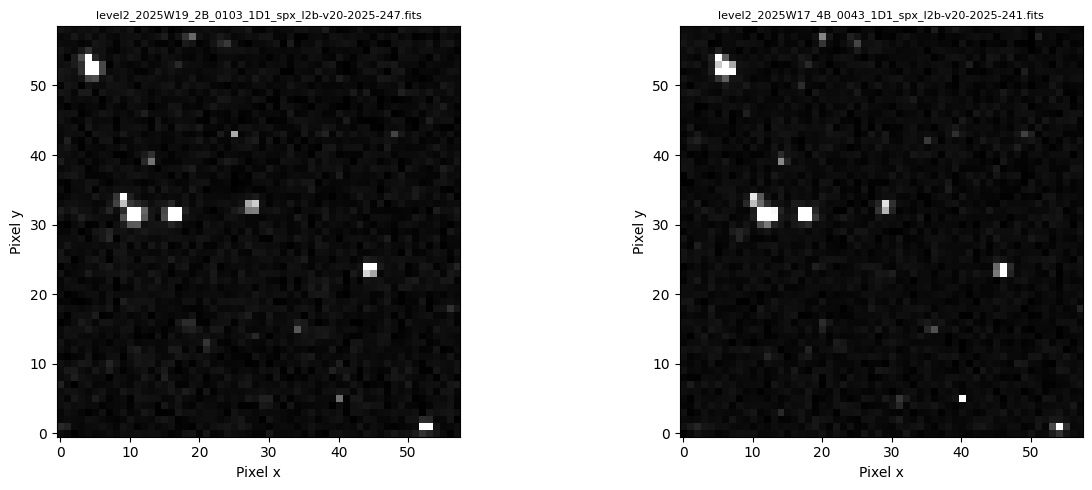

In [3]:
def get_image_hdu(hdul):
    # Prefer the named IMAGE extension; fall back only to a 2-D image array.
    for hdu in hdul:
        if hdu.name.upper() == 'IMAGE' and hdu.data is not None and np.asarray(hdu.data).ndim == 2:
            return hdu
    for hdu in hdul:
        if hdu.data is not None and np.asarray(hdu.data).ndim == 2:
            return hdu
    raise ValueError('No 2-D image extension found')

image_hdus = [get_image_hdu(h) for h in hduls]
images = [np.asarray(h.data, dtype=float) for h in image_hdus]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, img, name in zip(axes, images, fits_files):
    finite = np.isfinite(img)
    lo, hi = np.nanpercentile(img[finite], [2, 99.5])
    ax.imshow(img, origin='lower', cmap='gray', vmin=lo, vmax=hi)
    ax.set_title(name, fontsize=8)
    ax.set_xlabel('Pixel x'); ax.set_ylabel('Pixel y')
plt.tight_layout(); plt.show()


In [4]:
# Inspect WCS availability and image geometry. WCS may be stored in IMAGE or another header.
for name, hdu, img in zip(fits_files, image_hdus, images):
    print('\n', name, 'image shape:', img.shape)
    print('WCS-related header cards:')
    for key in ['CTYPE1','CTYPE2','CRPIX1','CRPIX2','CRVAL1','CRVAL2','CDELT1','CDELT2','CD1_1','CD1_2','CD2_1','CD2_2']:
        if key in hdu.header: print(key, '=', hdu.header[key])
    try:
        w = WCS(hdu.header)
        print(w)
    except Exception as e:
        print('Could not construct WCS from IMAGE header:', e)



 level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits image shape: (59, 58)
WCS-related header cards:
CTYPE1 = RA---TAN-SIP
CTYPE2 = DEC--TAN-SIP
CRPIX1 = 29.5
CRPIX2 = 29.5
CRVAL1 = 151.815384083
CRVAL2 = 2.82426000924
CDELT1 = 1.0
CDELT2 = 1.0
WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN-SIP' 'DEC--TAN-SIP'
CUNIT : 'deg' 'deg'
CRVAL : 151.815384083 2.82426000924
CRPIX : 29.5 29.5
PC1_1 PC1_2  : 0.00160155983584 -0.000659074666455
PC2_1 PC2_2  : -0.000598992169649 -0.00157567479559
CDELT : 1.0 1.0
NAXIS : 58  59

 level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-241.fits image shape: (59, 58)
WCS-related header cards:
CTYPE1 = RA---TAN-SIP
CTYPE2 = DEC--TAN-SIP
CRPIX1 = 29.5
CRPIX2 = 29.5
CRVAL1 = 151.813196838
CRVAL2 = 2.82494979256
CDELT1 = 1.0
CDELT2 = 1.0
WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN-SIP' 'DEC--TAN-SIP'
CUNIT : 'deg' 'deg'
CRVAL : 151.813196838 2.82494979256
CRPIX : 29.5 29.5
PC1_1 PC1_2  : 0.00160220868199 -0.000659338625887
PC2_1 PC2_2  : -0.0005999

## Initial source detection

This is a first-pass detector only. It uses a local background/noise estimate and DAOStarFinder. Crowded fields, extended sources, artifacts and SPHEREx-specific PSF/quality flags may require a more tailored pipeline. Review the plotted detections before using the CSV.


level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits columns: ['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']
Using centroid columns: x_centroid y_centroid
Detected sources: 6


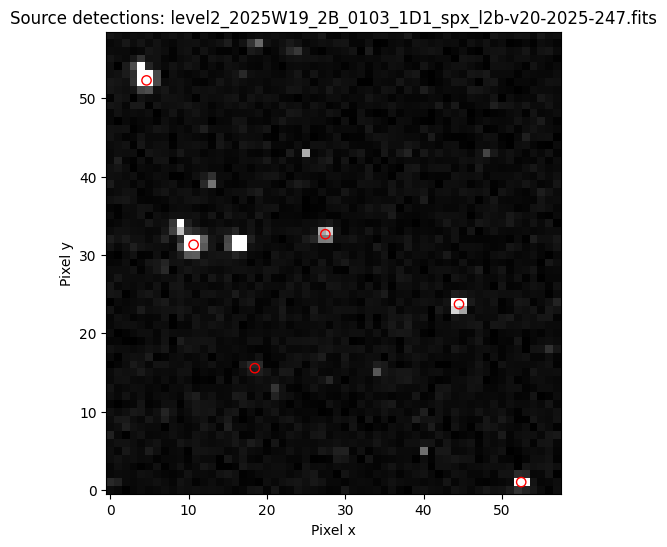

level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-241.fits columns: ['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']
Using centroid columns: x_centroid y_centroid
Detected sources: 4


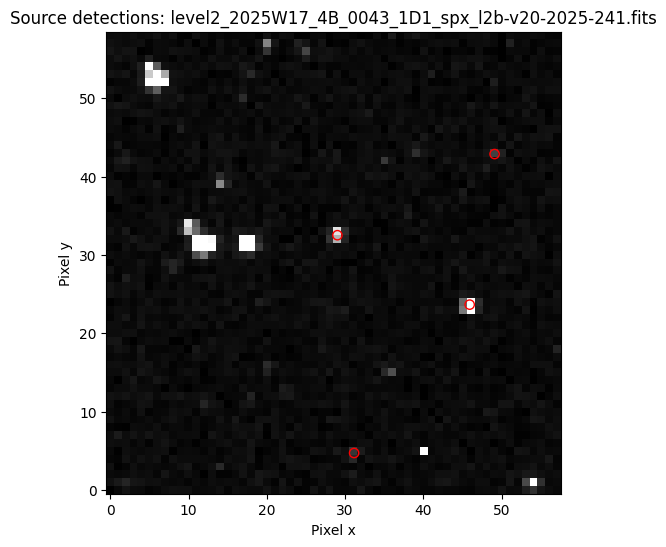

CSV successfully created!


,id,x_centroid,y_centroid,sharpness,roundness1,roundness2,n_pixels,peak,flux,mag,daofind_mag,observation_file,epoch_index,ra_deg,dec_deg
0,1,52.472379,0.983994,0.878110,0.155798,-0.338731,25,1.150297,2.636539,-1.052586,-2.345408,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...,1,151.873304,2.854552
1,2,18.451890,15.535215,0.538167,-0.727620,-0.150638,25,0.107236,0.318875,1.240949,-0.229420,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...,1,151.809134,2.852024
2,3,44.526082,23.706918,0.738018,-0.390639,-0.167602,25,1.284415,3.860811,-1.466696,-2.578946,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...,1,151.845551,2.823509
3,4,10.633028,31.298500,0.855807,-0.339036,-0.059348,25,10.317631,26.134899,-3.543052,-4.730551,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...,1,151.786175,2.831866
4,5,27.458713,32.643005,0.703969,0.324067,-0.163638,25,0.667989,2.064407,-0.786988,-1.911161,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...,1,151.812275,2.819662
5,6,4.622802,52.285605,0.875947,-0.407751,-0.046311,25,7.785508,18.934166,-3.193115,-4.409996,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...,1,151.762661,2.802389
6,1,31.137320,4.699111,0.950494,0.283786,-0.256761,25,0.161413,0.374343,1.066825,-0.192374,level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-24...,2,151.834369,2.862241
7,2,45.897941,23.647224,0.945682,0.215327,0.162517,25,1.909021,4.007619,-1.507216,-2.902190,level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-24...,2,151.845521,2.823524
8,3,29.006351,32.514579,0.873011,0.304555,0.279532,25,0.805774,2.030920,-0.769232,-2.009729,level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-24...,2,151.812574,2.819679
9,4,49.076867,42.878472,0.892836,0.241027,-0.018427,25,0.204082,0.390752,1.020248,-0.555345,level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-24...,2,151.837912,2.791305


In [10]:
tables = []

for idx, (name, hdul, hdu, img) in enumerate(
    zip(fits_files, hduls, image_hdus, images), start=1
):
    mean, median, std = sigma_clipped_stats(
        img, sigma=3.0, maxiters=5
    )

    if not np.isfinite(std) or std <= 0:
        print("Invalid noise estimate:", name)
        continue

    finder = DAOStarFinder(fwhm=3.0, threshold=5.0 * std)
    sources = finder(img - median)

    if sources is None or len(sources) == 0:
        print("No sources detected:", name)
        continue

    # Inspect the actual columns returned by Photutils
    print(name, "columns:", sources.colnames)

    # Convert Astropy table directly to a DataFrame
    df = pd.DataFrame({
        col: np.asarray(sources[col])
        for col in sources.colnames
    })

    # Normalize column names to handle underscores
    columns = {
        c.lower().replace("_", ""): c
        for c in df.columns
    }

    xcol = columns.get("xcentroid")
    ycol = columns.get("ycentroid")

    print("Using centroid columns:", xcol, ycol)

    if xcol is None or ycol is None:
        print("Centroid columns missing. Available:", list(df.columns))
        continue

    df["observation_file"] = name
    df["epoch_index"] = idx

    x = df[xcol].to_numpy()
    y = df[ycol].to_numpy()

    try:
        w = WCS(hdu.header)
        sky = w.pixel_to_world(x, y)
        df["ra_deg"] = sky.ra.deg
        df["dec_deg"] = sky.dec.deg
    except Exception as e:
        print("WCS conversion failed:", e)
        df["ra_deg"] = np.nan
        df["dec_deg"] = np.nan

    tables.append(df)

    print("Detected sources:", len(df))

    fig, ax = plt.subplots(figsize=(7, 6))
    lo, hi = np.nanpercentile(
        img[np.isfinite(img)], [2, 99.5]
    )
    ax.imshow(img, origin="lower", cmap="gray",
              vmin=lo, vmax=hi)
    ax.scatter(x, y, s=45, facecolors="none",
               edgecolors="red")
    ax.set_title("Source detections: " + name)
    ax.set_xlabel("Pixel x")
    ax.set_ylabel("Pixel y")
    plt.show()

if tables:
    detections = pd.concat(tables, ignore_index=True)
    detections.to_csv(
        "spherex_first_pass_detections.csv", index=False
    )
    print("CSV successfully created!")
    display(detections.head(20))
else:
    print("No valid source tables were produced.")

In [12]:

# Provisional matching threshold
threshold_arcsec = 5.0

matches["match_status"] = np.where(
    matches["separation_arcsec"] <= threshold_arcsec,
    "Close positional match",
    "Unmatched / possible false pairing"
)

print("MATCH CLASSIFICATION")
display(matches.sort_values("separation_arcsec"))

close_matches = matches[
    matches["separation_arcsec"] <= threshold_arcsec
]

print("Close matches:", len(close_matches))
print("Distant pairings:", len(matches) - len(close_matches))


MATCH CLASSIFICATION


,obs1_RA,obs1_Dec,obs2_RA,obs2_Dec,separation_arcsec,match_status
1,151.845551,2.823509,151.845521,2.823524,0.122981,Close positional match
3,151.812275,2.819662,151.812574,2.819679,1.075468,Close positional match
0,151.809134,2.852024,151.834369,2.862241,97.903097,Unmatched / possible false pairing
2,151.786175,2.831866,151.837912,2.791305,236.492663,Unmatched / possible false pairing


Close matches: 2
Distant pairings: 2


In [13]:

for name, hdul in zip(fits_files, hduls):
    print("\nFILE:", name)

    for hdu in hdul:
        if hdu.data is not None:
            for key in ["DATE-OBS", "MJD-OBS", "MJD-BEG",
                        "MJD-END", "EXPTIME"]:
                if key in hdu.header:
                    print(key, "=", hdu.header[key])



FILE: level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits
DATE-OBS = 2025-05-09T03:53:15.489
MJD-OBS = 60804.161984826
MJD-BEG = 60804.161984826
MJD-END = 60804.163317205
DATE-OBS = 2025-05-09T03:53:15.489
MJD-OBS = 60804.161984826
MJD-BEG = 60804.161984826
MJD-END = 60804.163317205
DATE-OBS = 2025-05-09T03:53:15.489
MJD-OBS = 60804.161984826
MJD-BEG = 60804.161984826
MJD-END = 60804.163317205
DATE-OBS = 2025-05-09T03:53:15.489
MJD-OBS = 60804.161984826
MJD-BEG = 60804.161984826
MJD-END = 60804.163317205

FILE: level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-241.fits
DATE-OBS = 2025-04-25T00:42:57.413
MJD-OBS = 60790.029831169
MJD-BEG = 60790.029831169
MJD-END = 60790.031163547
DATE-OBS = 2025-04-25T00:42:57.413
MJD-OBS = 60790.029831169
MJD-BEG = 60790.029831169
MJD-END = 60790.031163547
DATE-OBS = 2025-04-25T00:42:57.413
MJD-OBS = 60790.029831169
MJD-BEG = 60790.029831169
MJD-END = 60790.031163547
DATE-OBS = 2025-04-25T00:42:57.413
MJD-OBS = 60790.029831169
MJD-BEG = 60790.029831169
MJ

In [14]:

from astropy.wcs import WCS

for name, hdu, img in zip(fits_files, image_hdus, images):
    print("\nFILE:", name)

    w = WCS(hdu.header).celestial

    height, width = img.shape

    points = {
        "Center": (width/2, height/2),
        "Bottom-left": (0, 0),
        "Bottom-right": (width-1, 0),
        "Top-left": (0, height-1),
        "Top-right": (width-1, height-1)
    }

    for label, (x, y) in points.items():
        sky = w.pixel_to_world(x, y)
        print(
            label,
            "RA =", round(sky.ra.deg, 6),
            "Dec =", round(sky.dec.deg, 6)
        )



FILE: level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits
Center RA = 151.816824 Dec = 2.823691
Bottom-left RA = 151.789802 Dec = 2.887563
Bottom-right RA = 151.881213 Dec = 2.853385
Top-left RA = 151.751467 Dec = 2.796152
Top-right RA = 151.842895 Dec = 2.761973

FILE: level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-241.fits
Center RA = 151.814556 Dec = 2.824434
Bottom-left RA = 151.787534 Dec = 2.888308
Bottom-right RA = 151.878941 Dec = 2.854131
Top-left RA = 151.749202 Dec = 2.796893
Top-right RA = 151.840626 Dec = 2.762715


In [15]:

# Correct the epoch ordering using the observation dates
# The first file is May 9; the second is April 25.

detections["epoch_index"] = detections[
    "observation_file"
].apply(
    lambda name: 1 if "2025W17" in name else 2
)

# Epoch 1 = April 25
# Epoch 2 = May 9

print("Chronological source counts:")
print(detections.groupby("epoch_index").size())

display(
    detections[
        ["observation_file", "epoch_index",
         "ra_deg", "dec_deg", "flux"]
    ]
)


Chronological source counts:
epoch_index
1    4
2    6
dtype: int64


,observation_file,epoch_index,ra_deg,dec_deg,flux
0,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...,2,151.873304,2.854552,2.636539
1,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...,2,151.809134,2.852024,0.318875
2,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...,2,151.845551,2.823509,3.860811
3,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...,2,151.786175,2.831866,26.134899
4,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...,2,151.812275,2.819662,2.064407
5,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...,2,151.762661,2.802389,18.934166
6,level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-24...,1,151.834369,2.862241,0.374343
7,level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-24...,1,151.845521,2.823524,4.007619
8,level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-24...,1,151.812574,2.819679,2.030920
9,level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-24...,1,151.837912,2.791305,0.390752


In [16]:

from astropy.coordinates import SkyCoord
import astropy.units as u
from scipy.optimize import linear_sum_assignment

# Epoch 1 = April 25
# Epoch 2 = May 9

obs1 = detections[detections["epoch_index"] == 1].copy()
obs2 = detections[detections["epoch_index"] == 2].copy()

sky1 = SkyCoord(
    ra=obs1["ra_deg"].values * u.deg,
    dec=obs1["dec_deg"].values * u.deg
)

sky2 = SkyCoord(
    ra=obs2["ra_deg"].values * u.deg,
    dec=obs2["dec_deg"].values * u.deg
)

# All pairwise angular separations
sep = sky1[:, None].separation(sky2[None, :])

# One-to-one assignment
rows, cols = linear_sum_assignment(sep.arcsec)

# Keep only pairs within 5 arcseconds
valid = sep.arcsec[rows, cols] <= 5.0
rows = rows[valid]
cols = cols[valid]

# Calculate east/north positional offsets
east, north = sky1[rows].spherical_offsets_to(sky2[cols])

# Actual time interval from the FITS metadata
delta_days = 60804.161984826 - 60790.029831169

results = pd.DataFrame({
    "April_RA": obs1.iloc[rows]["ra_deg"].values,
    "April_Dec": obs1.iloc[rows]["dec_deg"].values,
    "May_RA": obs2.iloc[cols]["ra_deg"].values,
    "May_Dec": obs2.iloc[cols]["dec_deg"].values,
    "East_shift_arcsec": east.to(u.arcsec).value,
    "North_shift_arcsec": north.to(u.arcsec).value,
    "Separation_arcsec": sep.arcsec[rows, cols],
    "Motion_arcsec_per_day": (
        sep.arcsec[rows, cols] / delta_days
    )
})

print("CHRONOLOGICAL SOURCE MATCHES")
print("Time interval:", delta_days, "days")
display(results)
print("Matched pairs:", len(results))
print("Unmatched April detections:", len(obs1) - len(rows))
print("Unmatched May detections:", len(obs2) - len(cols))


CHRONOLOGICAL SOURCE MATCHES
Time interval: 14.132153657003073 days


,April_RA,April_Dec,May_RA,May_Dec,East_shift_arcsec,North_shift_arcsec,Separation_arcsec,Motion_arcsec_per_day
0,151.845521,2.823524,151.845551,2.823509,0.110467,-0.054048,0.122981,0.008702
1,151.812574,2.819679,151.812275,2.819662,-1.073606,-0.063260,1.075468,0.076101


Matched pairs: 2
Unmatched April detections: 2
Unmatched May detections: 4


In [17]:

for name, hdul in zip(fits_files, hduls):
    print("\n" + "="*60)
    print("FILE:", name)
    print("="*60)

    for i, hdu in enumerate(hdul):
        print("\nExtension:", i)
        print("Name:", hdu.name)

        if hdu.data is not None:
            print("Shape:", hdu.data.shape)
            print("Data type:", hdu.data.dtype)

        for key in ["BUNIT", "EXTNAME", "EXTVER",
                    "BZERO", "BSCALE"]:
            if key in hdu.header:
                print(key, "=", hdu.header[key])



FILE: level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits

Extension: 0
Name: PRIMARY

Extension: 1
Name: IMAGE
Shape: (59, 58)
Data type: >f4
BUNIT = MJy / sr
EXTNAME = IMAGE

Extension: 2
Name: FLAGS
Shape: (59, 58)
Data type: >i4
BUNIT = 
EXTNAME = FLAGS

Extension: 3
Name: VARIANCE
Shape: (59, 58)
Data type: >f4
BUNIT = MJy2 / sr2
EXTNAME = VARIANCE

Extension: 4
Name: ZODI
Shape: (59, 58)
Data type: >f4
BUNIT = MJy / sr
EXTNAME = ZODI

Extension: 5
Name: PSF
Shape: (121, 101, 101)
Data type: >f4
BUNIT = 
EXTNAME = PSF

Extension: 6
Name: WCS-WAVE
Shape: (1,)
Data type: (numpy.record, [('X', '>i4', (9,)), ('Y', '>i4', (9,)), ('VALUES', '>f4', (9, 9, 2))])
EXTNAME = WCS-WAVE

FILE: level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-241.fits

Extension: 0
Name: PRIMARY

Extension: 1
Name: IMAGE
Shape: (59, 58)
Data type: >f4
BUNIT = MJy / sr
EXTNAME = IMAGE

Extension: 2
Name: FLAGS
Shape: (59, 58)
Data type: >i4
BUNIT = 
EXTNAME = FLAGS

Extension: 3
Name: VARIANCE
Shape: (59, 58)
Data t

In [18]:

import numpy as np
import pandas as pd

for name, hdul in zip(fits_files, hduls):

    flags = hdul["FLAGS"].data
    variance = hdul["VARIANCE"].data

    print("\nFILE:", name)

    # Inspect quality flags
    values, counts = np.unique(flags, return_counts=True)

    print("\nQuality flag values:")
    print(pd.DataFrame({
        "flag_value": values,
        "pixel_count": counts
    }))

    # Inspect variance
    valid = np.isfinite(variance) & (variance >= 0)

    print("\nVariance statistics:")
    print("Valid pixels:", valid.sum())
    print("Median variance:", np.median(variance[valid]))
    print("Minimum variance:", np.min(variance[valid]))
    print("Maximum variance:", np.max(variance[valid]))

    # Inspect PSF dimensions
    print("\nPSF shape:", hdul["PSF"].data.shape)



FILE: level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits

Quality flag values:
   flag_value  pixel_count
0           0         2868
1           1            3
2           5            9
3        2053            1
4      131072            3
5      524288           66
6      524293            2
7      655360            1
8     2097152          469

Variance statistics:
Valid pixels: 3422
Median variance: 0.00039325817
Minimum variance: 0.00030853276
Maximum variance: 0.022253867

PSF shape: (121, 101, 101)

FILE: level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-241.fits

Quality flag values:
   flag_value  pixel_count
0           0         2876
1           1            4
2           5            6
3        2053            3
4      131072            3
5      524288           56
6      524293            1
7     2097152          473

Variance statistics:
Valid pixels: 3422
Median variance: 0.0003582685
Minimum variance: 0.0002621402
Maximum variance: 0.057271697

PSF shape: (121, 101, 101)


In [19]:

# SPHEREx quality flag bit positions
flag_names = {
    0: "TRANSIENT",
    1: "OVERFLOW",
    2: "SUR_ERROR",
    6: "NONFUNC",
    7: "DICHROIC",
    9: "MISSING_DATA",
    10: "HOT",
    11: "COLD",
    15: "NONLINEAR",
    17: "PERSIST",
    19: "OUTLIER",
    21: "SOURCE"
}

# Informational SOURCE is not automatically a bad flag.
bad_bits = [0, 1, 2, 6, 7, 9, 10, 11, 15, 17, 19]

file_map = dict(zip(fits_files, hduls))
quality_results = []

for _, row in detections.iterrows():

    name = row["observation_file"]
    hdul = file_map[name]

    flags = hdul["FLAGS"].data
    variance = hdul["VARIANCE"].data

    x = int(round(row["x_centroid"]))
    y = int(round(row["y_centroid"]))

    # Inspect a 3x3 pixel region around the source
    y0, y1 = max(0, y-1), min(flags.shape[0], y+2)
    x0, x1 = max(0, x-1), min(flags.shape[1], x+2)

    local_flags = flags[y0:y1, x0:x1]
    local_variance = variance[y0:y1, x0:x1]

    center_flag = int(flags[y, x])

    present = [
        flag_names[b]
        for b in flag_names
        if center_flag & (1 << b)
    ]

    bad_pixel_count = sum(
        bool(int(value) & sum(1 << b for b in bad_bits))
        for value in local_flags.flatten()
    )

    quality_results.append({
        "source_id": int(row["id"]),
        "epoch": int(row["epoch_index"]),
        "RA": row["ra_deg"],
        "Dec": row["dec_deg"],
        "center_flag": center_flag,
        "center_flag_meaning": ", ".join(present) or "NONE",
        "bad_pixels_in_3x3": bad_pixel_count,
        "pixels_in_3x3": local_flags.size,
        "median_local_variance": np.nanmedian(local_variance)
    })

quality_table = pd.DataFrame(quality_results)

display(quality_table)
quality_table.to_csv("spherex_source_quality.csv", index=False)

print("Saved spherex_source_quality.csv")


,source_id,epoch,RA,Dec,center_flag,center_flag_meaning,bad_pixels_in_3x3,pixels_in_3x3,median_local_variance
0,1,2,151.873304,2.854552,2097152,SOURCE,0,9,0.000518
1,2,2,151.809134,2.852024,2097152,SOURCE,0,9,0.000484
2,3,2,151.845551,2.823509,2097152,SOURCE,0,9,0.000466
3,4,2,151.786175,2.831866,2097152,SOURCE,0,9,0.000810
4,5,2,151.812275,2.819662,2097152,SOURCE,0,9,0.000480
5,6,2,151.762661,2.802389,2097152,SOURCE,0,9,0.000687
6,1,1,151.834369,2.862241,2097152,SOURCE,0,9,0.000410
7,2,1,151.845521,2.823524,2097152,SOURCE,0,9,0.000526
8,3,1,151.812574,2.819679,2097152,SOURCE,0,9,0.000465
9,4,1,151.837912,2.791305,2097152,SOURCE,0,9,0.000390


Saved spherex_source_quality.csv


In [21]:
# Compare brightness for the two matched sources

for _, match in results.iterrows():

    ra1, dec1 = match["April_RA"], match["April_Dec"]
    ra2, dec2 = match["May_RA"], match["May_Dec"]

    # Find nearest detections in each epoch
    april = detections[detections["epoch_index"] == 1].copy()
    may = detections[detections["epoch_index"] == 2].copy()

    april["distance"] = np.sqrt(
        ((april["ra_deg"] - ra1) * np.cos(np.radians(dec1)))**2
        + (april["dec_deg"] - dec1)**2
    ) * 3600

    may["distance"] = np.sqrt(
        ((may["ra_deg"] - ra2) * np.cos(np.radians(dec2)))**2
        + (may["dec_deg"] - dec2)**2
    ) * 3600

    a = april.loc[april["distance"].idxmin()]
    m = may.loc[may["distance"].idxmin()]

    print("\nMatched source:")
    print("April flux:", a["flux"])
    print("May flux:", m["flux"])
    print("Flux change (%):",
          100 * (m["flux"] - a["flux"]) / a["flux"])


Matched source:
April flux: 4.0076189041137695
May flux: 3.860811084508896
Flux change (%): -3.6632180633287588

Matched source:
April flux: 2.030919924378395
May flux: 2.0644070208072662
Flux change (%): 1.6488634547775471


In [22]:
import pandas as pd

print("DATAFRAMES CURRENTLY LOADED:\n")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\nVariable: {name}")
        print("Shape:", obj.shape)
        print("Columns:", list(obj.columns))


DATAFRAMES CURRENTLY LOADED:


Variable: df
Shape: (4, 15)
Columns: ['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag', 'observation_file', 'epoch_index', 'ra_deg', 'dec_deg']

Variable: detections
Shape: (10, 15)
Columns: ['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag', 'observation_file', 'epoch_index', 'ra_deg', 'dec_deg']

Variable: obs1
Shape: (4, 15)
Columns: ['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag', 'observation_file', 'epoch_index', 'ra_deg', 'dec_deg']

Variable: obs2
Shape: (6, 15)
Columns: ['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag', 'observation_file', 'epoch_index', 'ra_deg', 'dec_deg']

Variable: matches
Shape: (4, 6)
Columns: ['obs1_RA', 'obs1_Dec', 'obs2_RA', 

In [23]:
import numpy as np

print("LOADED IMAGE AND FITS VARIABLES:\n")

for name, obj in globals().copy().items():
    if isinstance(obj, np.ndarray):
        print(name, " | Shape:", obj.shape, "| Type:", obj.dtype)

    elif hasattr(obj, "__class__") and "HDUList" in str(type(obj)):
        print("\nFITS FILE:", name)
        for i, hdu in enumerate(obj):
            print(i, hdu.name,
                  None if hdu.data is None else hdu.data.shape)

LOADED IMAGE AND FITS VARIABLES:

axes  | Shape: (2,) | Type: object
img  | Shape: (59, 58) | Type: float64
finite  | Shape: (59, 58) | Type: bool

FITS FILE: hdul
0 PRIMARY None
1 IMAGE (59, 58)
2 FLAGS (59, 58)
3 VARIANCE (59, 58)
4 ZODI (59, 58)
5 PSF (121, 101, 101)
6 WCS-WAVE (1,)
separations  | Shape: (6, 4) | Type: float64
rows  | Shape: (2,) | Type: int64
cols  | Shape: (2,) | Type: int64
sep  | Shape: (4, 6) | Type: float64
valid  | Shape: (59, 58) | Type: bool
east  | Shape: (2,) | Type: float64
north  | Shape: (2,) | Type: float64
flags  | Shape: (59, 58) | Type: >i4
variance  | Shape: (59, 58) | Type: >f4
values  | Shape: (8,) | Type: >i4
counts  | Shape: (8,) | Type: int64
local_flags  | Shape: (3, 3) | Type: >i4
local_variance  | Shape: (3, 3) | Type: >f4


In [25]:
import os

from pathlib import Path

filenames = detections['observation_file'].unique()

for filename in filenames:
    matches = list(Path('/content').rglob(filename))

    print("\nFITS:", filename)

    if matches:
        print("FOUND:", matches[0])
    else:
        print("NOT FOUND")


FITS: level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits
FOUND: /content/level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits

FITS: level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-241.fits
FOUND: /content/level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-241.fits


In [27]:

from astropy.io import fits
from pathlib import Path

april_file = "/content/level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-241.fits"
may_file = "/content/level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits"

fits_data = {
    "April": fits.open(april_file),
    "May": fits.open(may_file)
}

for epoch, hdul in fits_data.items():
    print("\n", epoch)
    print("Image:", hdul["IMAGE"].data.shape)
    print("Variance:", hdul["VARIANCE"].data.shape)
    print("Flags:", hdul["FLAGS"].data.shape)



 April
Image: (59, 58)
Variance: (59, 58)
Flags: (59, 58)

 May
Image: (59, 58)
Variance: (59, 58)
Flags: (59, 58)


In [28]:

import numpy as np

for epoch, hdul in fits_data.items():
    variance = np.asarray(
        hdul["VARIANCE"].data, dtype=float
    )

    valid = np.isfinite(variance) & (variance >= 0)

    pixel_sigma = np.sqrt(variance[valid])

    print("\n", epoch)
    print("Median pixel uncertainty:", np.median(pixel_sigma))
    print("Mean pixel uncertainty:", np.mean(pixel_sigma))
    print("Valid pixels:", valid.sum())



 April
Median pixel uncertainty: 0.018927981988662572
Mean pixel uncertainty: 0.01963442904581053
Valid pixels: 3422

 May
Median pixel uncertainty: 0.019830738121541954
Mean pixel uncertainty: 0.02045965141287156
Valid pixels: 3422


In [29]:
import numpy as np
import pandas as pd

from photutils.aperture import (
    CircularAperture,
    CircularAnnulus,
    aperture_photometry
)

source_results = []

# April = epoch 1, May = epoch 2
for epoch, epoch_index in [("April", 1), ("May", 2)]:

    hdul = fits_data[epoch]

    image = np.asarray(hdul["IMAGE"].data, dtype=float)
    variance = np.asarray(hdul["VARIANCE"].data, dtype=float)

    # Select detections from this observation
    sources = detections[detections["epoch_index"] == epoch_index]

    for _, source in sources.iterrows():

        x = float(source["x_centroid"])
        y = float(source["y_centroid"])

        position = [(x, y)]

        # Source aperture and surrounding background annulus
        aperture = CircularAperture(position, r=3)
        annulus = CircularAnnulus(
            position, r_in=5, r_out=8
        )

        # Measure source and local background
        source_sum = aperture_photometry(
            image, aperture
        )["aperture_sum"][0]

        annulus_sum = aperture_photometry(
            image, annulus
        )["aperture_sum"][0]

        # Estimate background per pixel
        annulus_mask = annulus.to_mask(method="center")[0]
        annulus_data = annulus_mask.multiply(image)

        annulus_pixels = annulus_data[
            (annulus_mask.data > 0) &
            np.isfinite(annulus_data)
        ]

        if len(annulus_pixels) == 0:
            continue

        background = np.median(annulus_pixels)

        # Background-subtracted source flux
        aperture_area = aperture.area
        net_flux = source_sum - background * aperture_area

        # Sum pixel variances inside the source aperture
        variance_mask = aperture.to_mask(method="center")[0]
        variance_data = variance_mask.multiply(variance)

        valid_variance = (
            np.isfinite(variance_data) &
            (variance_mask.data > 0)
        )

        aperture_variance = np.sum(
            variance_data[valid_variance] *
            variance_mask.data[valid_variance]
        )

        # Approximate uncertainty in the estimated background
        annulus_variance = np.nanmedian(
            variance[
                (annulus_mask.to_image(image.shape) > 0) &
                np.isfinite(variance)
            ]
        )

        background_error_squared = (
            aperture_area**2 * annulus_variance /
            max(len(annulus_pixels), 1)
        )

        total_uncertainty = np.sqrt(
            aperture_variance + background_error_squared
        )

        snr = (
            net_flux / total_uncertainty
            if total_uncertainty > 0 else np.nan
        )

        source_results.append({
            "Epoch": epoch,
            "X": x,
            "Y": y,
            "Net_Flux": net_flux,
            "Flux_Uncertainty": total_uncertainty,
            "SNR": snr
        })

source_photometry = pd.DataFrame(source_results)

display(source_photometry.round(5))

,Epoch,X,Y,Net_Flux,Flux_Uncertainty,SNR
0,April,31.13732,4.69911,0.56288,0.11530,4.88183
1,April,45.89794,23.64722,4.03534,0.13253,30.44869
2,April,29.00635,32.51458,2.03416,0.11900,17.09373
3,April,49.07687,42.87847,0.56899,0.11293,5.03838
4,May,52.47238,0.98399,9.04112,0.12133,74.51480
5,May,18.45189,15.53521,0.31488,0.12507,2.51750
6,May,44.52608,23.70692,4.05667,0.13626,29.77170
7,May,10.63303,31.29850,27.46769,0.22157,123.96781
8,May,27.45871,32.64301,2.13196,0.12798,16.65900
9,May,4.62280,52.28561,20.77120,0.19818,104.80755


In [30]:
source_photometry.to_csv(
    "SPHEREx_source_photometry.csv",
    index=False
)

print("Photometry results saved successfully!")

Photometry results saved successfully!


In [31]:
# Display the matched sources and their positional changes

print("MATCHED SOURCES:")
display(close_matches)

print("\nPOSITIONAL MOVEMENT:")
display(results.round(5))

MATCHED SOURCES:


,obs1_RA,obs1_Dec,obs2_RA,obs2_Dec,separation_arcsec,match_status
1,151.845551,2.823509,151.845521,2.823524,0.122981,Close positional match
3,151.812275,2.819662,151.812574,2.819679,1.075468,Close positional match



POSITIONAL MOVEMENT:


,April_RA,April_Dec,May_RA,May_Dec,East_shift_arcsec,North_shift_arcsec,Separation_arcsec,Motion_arcsec_per_day
0,151.84552,2.82352,151.84555,2.82351,0.11047,-0.05405,0.12298,0.0087
1,151.81257,2.81968,151.81228,2.81966,-1.07361,-0.06326,1.07547,0.0761


In [33]:
results.to_csv("SPHEREx_source_motion.csv", index=False)

print("Movement results saved successfully!")

Movement results saved successfully!


In [35]:
from astropy.io import fits
import numpy as np

new_file = "/content/level2_2026W22_1A_0214_2D1_spx_l2b-v25-2026-150.fits"

new_hdul = fits.open(new_file)

print("FITS extensions:")
for hdu in new_hdul:
    print(hdu.name, getattr(hdu.data, "shape", None))

print("\nImage dimensions:")
print(new_hdul["IMAGE"].data.shape)

print("\nImage data range:")
print(np.nanmin(new_hdul["IMAGE"].data))
print(np.nanmax(new_hdul["IMAGE"].data))

print("\nWCS information:")
print(new_hdul["IMAGE"].header)

FITS extensions:
PRIMARY None
IMAGE (59, 58)
FLAGS (59, 58)
VARIANCE (59, 58)
ZODI (59, 58)
PSF (121, 101, 101)
WCS-WAVE (1,)

Image dimensions:
(59, 58)

Image data range:
-1.7887591
8.874249

WCS information:
XTENSION= 'IMAGE   '           / Image extension                                BITPIX  =                  -32 / array data type                                NAXIS   =                    2 / number of array dimensions                     NAXIS1  =                   58                                                  NAXIS2  =                   59                                                  PCOUNT  =                    0 / number of parameters                           GCOUNT  =                    1 / number of groups                               EXTNAME = 'IMAGE   '           / extension name                                 EXTTYPE = 'IMAGE   '           / Extension supports mask overlay                BUNIT   = 'MJy / sr'           / Unit of pixel value                 

## Important interpretation limits

- Do not compare raw pixel `(x,y)` values across the two cutouts until they are registered onto a common grid.
- Confirm the correct WCS is used. Some SPHEREx products may store spatial/spectral coordinate information in separate extensions or headers.
- Apply quality masks from `FLAGS` and account for `VARIANCE` before accepting detections.
- A source detected in one image but not the other is not automatically moving; it may be below threshold, masked, blended, or affected by artifacts.
- Only call an object a candidate after cross-matching, uncertainty/significance checks and independent validation.


In [36]:
from astropy.wcs import WCS

wcs_new = WCS(new_hdul["IMAGE"].header)

target_ra = 151.81441452
target_dec = 2.82631029

x, y = wcs_new.world_to_pixel_values(
    target_ra, target_dec
)

print("Target pixel coordinates:", x, y)
print("Image dimensions:", new_hdul["IMAGE"].data.shape)

if 0 <= x < 58 and 0 <= y < 59:
    print("TARGET IS INSIDE THE IMAGE")
else:
    print("TARGET IS OUTSIDE THE IMAGE")

Target pixel coordinates: 28.84869757573839 28.74008888716715
Image dimensions: (59, 58)
TARGET IS INSIDE THE IMAGE


In [37]:
from photutils.detection import DAOStarFinder
import numpy as np

image3 = np.asarray(
    new_hdul["IMAGE"].data,
    dtype=float
)

variance3 = np.asarray(
    new_hdul["VARIANCE"].data,
    dtype=float
)

# Estimate background and noise
background3 = np.nanmedian(image3)
noise3 = np.sqrt(np.nanmedian(variance3))

# Detect sources
finder3 = DAOStarFinder(
    fwhm=2.5,
    threshold=5.0 * noise3
)

sources3 = finder3(
    image3 - background3
)

if sources3 is not None:
    sources3 = sources3.to_pandas()
    print("Number of sources detected:", len(sources3))
    display(sources3)
else:
    print("No sources detected.")

Number of sources detected: 3


,id,x_centroid,y_centroid,sharpness,roundness1,roundness2,n_pixels,peak,flux,mag,daofind_mag
0,1,12.292430,31.480499,0.810747,-0.362236,0.159965,25,8.523066,26.200024,-3.545754,-4.602140
1,2,14.367158,39.482748,0.681007,-0.523983,-0.104504,25,0.212781,0.798438,0.244396,-0.707954
2,3,6.326888,52.470103,0.746060,-0.384395,0.208445,25,5.560400,19.532970,-3.226921,-4.179598


In [38]:
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u
import pandas as pd

# Convert new source pixel positions to RA/Dec
wcs_new = WCS(new_hdul["IMAGE"].header).celestial

world_coords = wcs_new.pixel_to_world(
    sources3["x_centroid"].values,
    sources3["y_centroid"].values
)

sources3["ra_deg"] = world_coords.ra.deg
sources3["dec_deg"] = world_coords.dec.deg

print("THIRD EPOCH SOURCE COORDINATES")
display(
    sources3[
        ["id", "x_centroid", "y_centroid", "ra_deg", "dec_deg", "flux"]
    ].round(6)
)

THIRD EPOCH SOURCE COORDINATES


,id,x_centroid,y_centroid,ra_deg,dec_deg,flux
0,1,12.292430,31.480499,151.786030,2.831894,26.200024
1,2,14.367158,39.482748,151.784060,2.818048,0.798438
2,3,6.326888,52.470103,151.762552,2.802395,19.532970


In [39]:
from astropy.coordinates import SkyCoord
import astropy.units as u

new_coords = SkyCoord(
    ra=sources3["ra_deg"].values * u.deg,
    dec=sources3["dec_deg"].values * u.deg
)

for epoch, epoch_index in [("April", 1), ("May", 2)]:

    old = detections[
        detections["epoch_index"] == epoch_index
    ].copy()

    old_coords = SkyCoord(
        ra=old["ra_deg"].values * u.deg,
        dec=old["dec_deg"].values * u.deg
    )

    print(f"\nNEW SOURCES vs {epoch.upper()}")

    for i, coord in enumerate(new_coords):

        separation = coord.separation(old_coords)
        nearest = separation.argmin()

        print(
            f"New source {i+1} -> "
            f"Old source {old.iloc[nearest]['id']}: "
            f"{separation[nearest].arcsec:.3f} arcsec"
        )


NEW SOURCES vs APRIL
New source 1 -> Old source 3: 105.086 arcsec
New source 2 -> Old source 3: 102.695 arcsec
New source 3 -> Old source 3: 190.321 arcsec

NEW SOURCES vs MAY
New source 1 -> Old source 4: 0.534 arcsec
New source 2 -> Old source 4: 50.324 arcsec
New source 3 -> Old source 6: 0.394 arcsec


In [40]:
for epoch, epoch_index in [("APRIL", 1), ("MAY", 2)]:

    print(f"\n{epoch} SOURCES")

    old = detections[
        detections["epoch_index"] == epoch_index
    ]

    display(
        old[
            ["id", "ra_deg", "dec_deg", "flux"]
        ].round(6)
    )

print("\nMAY 2026 SOURCES")

display(
    sources3[
        ["id", "ra_deg", "dec_deg", "flux"]
    ].round(6)
)


APRIL SOURCES


,id,ra_deg,dec_deg,flux
6,1,151.834369,2.862241,0.374343
7,2,151.845521,2.823524,4.007619
8,3,151.812574,2.819679,2.030920
9,4,151.837912,2.791305,0.390752



MAY SOURCES


,id,ra_deg,dec_deg,flux
0,1,151.873304,2.854552,2.636539
1,2,151.809134,2.852024,0.318875
2,3,151.845551,2.823509,3.860811
3,4,151.786175,2.831866,26.134899
4,5,151.812275,2.819662,2.064407
5,6,151.762661,2.802389,18.934166



MAY 2026 SOURCES


,id,ra_deg,dec_deg,flux
0,1,151.786030,2.831894,26.200024
1,2,151.784060,2.818048,0.798438
2,3,151.762552,2.802395,19.532970


In [41]:
from astropy.coordinates import SkyCoord
import astropy.units as u
import pandas as pd

# May 2025 matched sources: IDs 4 and 6
may_sources = detections[
    (detections["epoch_index"] == 2) &
    (detections["id"].isin([4, 6]))
].sort_values("id")

# May 2026 matched sources: IDs 1 and 3
new_sources = sources3[
    sources3["id"].isin([1, 3])
].sort_values("id")

old_coords = SkyCoord(
    ra=may_sources["ra_deg"].values * u.deg,
    dec=may_sources["dec_deg"].values * u.deg
)

new_coords = SkyCoord(
    ra=new_sources["ra_deg"].values * u.deg,
    dec=new_sources["dec_deg"].values * u.deg
)

# Observation dates in MJD
mjd_2025 = 60804.161985
mjd_2026 = 61186.361248

days = mjd_2026 - mjd_2025

motion_results = []

for i in range(len(old_coords)):
    separation = old_coords[i].separation(new_coords[i])

    east, north = old_coords[i].spherical_offsets_to(
        new_coords[i]
    )

    motion_results.append({
        "Source_Pair": i + 1,
        "May2025_Source_ID": int(may_sources.iloc[i]["id"]),
        "May2026_Source_ID": int(new_sources.iloc[i]["id"]),
        "Separation_arcsec": separation.arcsec,
        "East_shift_arcsec": east.arcsec,
        "North_shift_arcsec": north.arcsec,
        "Motion_arcsec_per_day": separation.arcsec / days,
        "Time_interval_days": days
    })

motion_2025_2026 = pd.DataFrame(motion_results)

display(motion_2025_2026.round(6))

,Source_Pair,May2025_Source_ID,May2026_Source_ID,Separation_arcsec,East_shift_arcsec,North_shift_arcsec,Motion_arcsec_per_day,Time_interval_days
0,1,4,1,0.533560,-0.524186,0.099576,0.001396,382.199263
1,2,6,3,0.394072,-0.393530,0.020655,0.001031,382.199263


In [42]:
from astropy.coordinates import SkyCoord
import astropy.units as u
import numpy as np

# All May 2025 and May 2026 detections
may25 = detections[detections["epoch_index"] == 2].copy()
may26 = sources3.copy()

coords25 = SkyCoord(
    may25["ra_deg"].values * u.deg,
    may25["dec_deg"].values * u.deg
)

coords26 = SkyCoord(
    may26["ra_deg"].values * u.deg,
    may26["dec_deg"].values * u.deg
)

idx, sep, _ = coords25.match_to_catalog_sky(coords26)

alignment = []

for i in range(len(may25)):
    alignment.append({
        "May2025_ID": int(may25.iloc[i]["id"]),
        "Nearest_May2026_ID": int(may26.iloc[idx[i]]["id"]),
        "Separation_arcsec": sep[i].arcsec
    })

import pandas as pd
alignment_df = pd.DataFrame(alignment)

display(alignment_df.round(5))

,May2025_ID,Nearest_May2026_ID,Separation_arcsec
0,1,1,324.22797
1,2,1,110.23995
2,3,1,216.13523
3,4,1,0.53356
4,5,2,101.61955
5,6,3,0.39407


In [43]:
import numpy as np
import pandas as pd

# Use only the two close matched pairs
east_shifts = motion_2025_2026["East_shift_arcsec"].values
north_shifts = motion_2025_2026["North_shift_arcsec"].values

# Estimate common systematic offset
median_east = np.median(east_shifts)
median_north = np.median(north_shifts)

print("Estimated common east offset:", median_east, "arcsec")
print("Estimated common north offset:", median_north, "arcsec")

# Calculate residual movement after removing common offset
motion_2025_2026["Residual_East_arcsec"] = (
    east_shifts - median_east
)

motion_2025_2026["Residual_North_arcsec"] = (
    north_shifts - median_north
)

motion_2025_2026["Residual_Separation_arcsec"] = np.sqrt(
    motion_2025_2026["Residual_East_arcsec"]**2 +
    motion_2025_2026["Residual_North_arcsec"]**2
)

display(motion_2025_2026.round(6))

Estimated common east offset: -0.4588580279453053 arcsec
Estimated common north offset: 0.06011504559250205 arcsec


,Source_Pair,May2025_Source_ID,May2026_Source_ID,Separation_arcsec,East_shift_arcsec,North_shift_arcsec,Motion_arcsec_per_day,Time_interval_days,Residual_East_arcsec,Residual_North_arcsec,Residual_Separation_arcsec
0,1,4,1,0.533560,-0.524186,0.099576,0.001396,382.199263,-0.065328,0.03946,0.076321
1,2,6,3,0.394072,-0.393530,0.020655,0.001031,382.199263,0.065328,-0.03946,0.076321


In [44]:
import numpy as np
import pandas as pd

# Calculate all pairwise angular separations
from astropy.coordinates import SkyCoord
import astropy.units as u

coords25 = SkyCoord(
    may25["ra_deg"].values * u.deg,
    may25["dec_deg"].values * u.deg
)

coords26 = SkyCoord(
    may26["ra_deg"].values * u.deg,
    may26["dec_deg"].values * u.deg
)

# Match each source uniquely using Hungarian assignment
from scipy.optimize import linear_sum_assignment

distance_matrix = coords25[:, None].separation(
    coords26[None, :]
).arcsec

row_ind, col_ind = linear_sum_assignment(distance_matrix)

reference_matches = []

for i, j in zip(row_ind, col_ind):
    reference_matches.append({
        "May2025_ID": int(may25.iloc[i]["id"]),
        "May2026_ID": int(may26.iloc[j]["id"]),
        "Separation_arcsec": distance_matrix[i, j]
    })

reference_matches = pd.DataFrame(reference_matches)

display(reference_matches.round(5))

,May2025_ID,May2026_ID,Separation_arcsec
0,4,1,0.53356
1,5,2,101.61955
2,6,3,0.39407


In [45]:
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.wcs import WCS
from photutils.detection import DAOStarFinder
from astropy.stats import mad_std

observations = {
    "April_2025": "level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-241.fits",
    "May_2025": "level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-247.fits",
    "May_2026": "level2_2026W22_1A_0214_2D1_spx_l2b-v25-2026-150(1).fits"
}

all_sources = []

for epoch, filename in observations.items():

    hdul = fits.open("/content/" + filename)

    image = np.asarray(hdul["IMAGE"].data, dtype=float)
    variance = np.asarray(hdul["VARIANCE"].data, dtype=float)

    background = np.nanmedian(image)
    noise = mad_std(image, ignore_nan=True)

    finder = DAOStarFinder(
        fwhm=2.5,
        threshold=5 * noise
    )

    sources = finder(image - background)

    if sources is None:
        print(epoch, ": No sources detected")
        continue

    df = sources.to_pandas()

    wcs = WCS(hdul["IMAGE"].header).celestial

    sky = wcs.pixel_to_world(
        df["x_centroid"].values,
        df["y_centroid"].values
    )

    df["RA_deg"] = sky.ra.deg
    df["Dec_deg"] = sky.dec.deg
    df["Epoch"] = epoch
    df["Image"] = filename

    all_sources.append(df)

    print(epoch, ":", len(df), "sources detected")

    hdul.close()

combined = pd.concat(all_sources, ignore_index=True)

combined.to_csv(
    "/content/SPHEREx_three_epoch_detections.csv",
    index=False
)

print("\nTOTAL DETECTIONS:", len(combined))
display(combined)

print("\nCSV SAVED SUCCESSFULLY")

April_2025 : 3 sources detected
May_2025 : 6 sources detected
May_2026 : 42 sources detected

TOTAL DETECTIONS: 51


,id,x_centroid,y_centroid,sharpness,roundness1,roundness2,n_pixels,peak,flux,mag,daofind_mag,RA_deg,Dec_deg,Epoch,Image
0,1,20.116983,15.480393,0.966389,0.221593,0.225456,25,0.119872,0.173033,1.904678,-0.019119,151.809572,2.851856,April_2025,level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-24...
1,2,29.005779,32.490068,0.938237,0.337900,0.300839,25,0.805179,2.023190,-0.765092,-2.013742,151.812589,2.819718,April_2025,level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-24...
2,3,49.071142,42.891575,0.960058,0.213920,-0.054122,25,0.203488,0.383022,1.041942,-0.558775,151.837895,2.791288,April_2025,level2_2025W17_4B_0043_1D1_spx_l2b-v20-2025-24...
3,1,52.446064,0.982298,0.943134,0.092727,-0.373824,25,1.149535,2.627387,-1.048810,-2.344410,151.873263,2.854570,May_2025,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...
4,2,18.491067,15.543003,0.607095,-0.747663,-0.204349,25,0.106474,0.308960,1.275244,-0.175200,151.809192,2.851988,May_2025,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...
5,3,44.553560,23.697671,0.804465,-0.402616,-0.182611,25,1.283652,3.850896,-1.463905,-2.561975,151.845601,2.823507,May_2025,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...
6,4,10.619883,31.307720,0.923284,-0.344838,-0.064951,25,10.316868,26.124984,-3.542640,-4.724783,151.786148,2.831860,May_2025,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...
7,5,27.439548,32.625757,0.773852,0.311252,-0.165395,25,0.667226,2.054492,-0.781761,-1.885030,151.812256,2.819700,May_2025,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...
8,6,4.607966,52.289166,0.943224,-0.422489,-0.057772,25,7.784745,18.924252,-3.192547,-4.406284,151.762635,2.802392,May_2025,level2_2025W19_2B_0103_1D1_spx_l2b-v20-2025-24...
9,1,156.671173,0.513913,0.847927,0.624778,0.091930,25,67.656834,193.947806,-5.719212,-6.667660,151.984126,2.921881,May_2026,level2_2026W22_1A_0214_2D1_spx_l2b-v25-2026-15...



CSV SAVED SUCCESSFULLY
